In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import matplotlib.dates as mdates

pd.set_option('display.max_columns', None)

In [3]:
import os
os.getcwd()

'C:\\Users\\Florini'

Current non-coordinated launch data available

In [13]:
feb8_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Feb8-25-Dlog39CF.csv')
apr4_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Apr4-25-Dlog09.csv')
jun1_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Jun1-25-Bravo CW Datalogger Coincident - Bravo CW Datalogger Coincident.csv')
jul20_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Jul20-25-Alpha CW Datalogger 3-in-Coincident - Alpha CW Datalogger 3-in-Coincident.csv')
aug24_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Aug24-25-CW-1 (Claire Balloon) Datalogger - CW-1 (Claire Balloon) Datalogger.csv')
oct4_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Oct4-25-AHD009 - AHD009.csv')
mar28_df = pd.read_csv('STAR\Data\Pre-Everything CSV\Mar28-26-DataLogger.csv')

In [14]:
feb8_df.rename(columns={'Accelerometer x': 'Accel x', 'Accelerometer y': 'Accel y', 'Accelerometer z': 'Accel z',
                       'Gyroscope x' : 'Gyro x', 'Gyroscope y' : 'Gyro y', 'Gyroscope z' : 'Gyro z'}, inplace=True)
apr4_df.rename(columns={'Accelerometer x': 'Accel x', 'Accelerometer y': 'Accel y', 'Accelerometer z': 'Accel z',
                       'Gyroscope x' : 'Gyro x', 'Gyroscope y' : 'Gyro y', 'Gyroscope z' : 'Gyro z'}, inplace=True)
jun1_df.rename(columns={'Temperature[C]': 'Temperature [C]', 'Pressure[Pa]':'Pressure [Pa]'}, inplace=True)
jul20_df.rename(columns={'Temperature[C]': 'Temperature [C]', 'Pressure[Pa]':'Pressure [Pa]'}, inplace=True)
aug24_df.rename(columns={'Temperature[C]': 'Temperature [C]', 'Pressure[Pa]':'Pressure [Pa]'}, inplace=True)
oct4_df.rename(columns={'Temperature[C]': 'Temperature [C]', 'Pressure[Pa]':'Pressure [Pa]'}, inplace=True)
mar28_df.rename(columns={'Temperature[C]': 'Temperature [C]', 'Pressure[Pa]':'Pressure [Pa]'}, inplace=True)

In [15]:
noncoor_df = pd.concat([feb8_df,apr4_df,jun1_df,jul20_df,aug24_df,oct4_df,mar28_df])

yyyy_converted = pd.to_datetime(noncoor_df['Date[MM/DD/YYYY]'], errors='coerce').dt.strftime('%m/%d/%y')
noncoor_df['Date [MM/DD/YY]'] = noncoor_df['Date [MM/DD/YY]'].fillna(yyyy_converted)
noncoor_df = noncoor_df.drop(columns=['Date[MM/DD/YYYY]'])

noncoor_df

,Events G1,Delta E G1,Events G2,Delta E G2,Temperature [C],Pressure [Pa],Date [MM/DD/YY],RTC_[HMS],Latitude,Longitude,Altitude,Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Accel-Gyro Temp [c],Mag x,Mag y,Mag z,Time,RTC [H:M:S],Events CW1,Events CW2,Event G1,Event G2,RTC[H:M:S EST],Timer[S],Altitude[m],Battery[],Events CW1&2,Events CW1&2&3
0,2.0,1.0,0.0,0.0,6.08,100937.28,2/8/2025,14:58:51,40.17347,-77.40319,140.60001,11,0.47737,0.30748,-9.53899,0.05009,-0.04032,-0.06964,3.0625,-38.01520,6.78164,44.70915,11/10/2024 9:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3.0,1.0,0.0,0.0,6.09,100938.09,2/8/2025,14:58:53,40.17347,-77.40319,141.00000,11,0.43071,0.24407,-9.66940,0.05009,-0.05131,-0.06475,3.1250,-38.32213,6.78164,43.87606,11/10/2024 9:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,1.0,0.0,0.0,6.10,100934.77,2/8/2025,14:58:53,40.17347,-77.40319,141.00000,11,0.41635,0.25484,-9.64786,0.05131,-0.07453,-0.06720,3.1250,-38.49751,6.91318,43.97837,11/10/2024 9:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5.0,1.0,0.0,0.0,6.10,100934.55,2/8/2025,14:58:55,40.17352,-77.40314,144.70000,12,0.50010,0.29073,-9.59402,0.04765,-0.03054,-0.06720,3.1250,-38.87752,7.07395,44.40222,11/10/2024 9:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,6.0,1.0,0.0,0.0,6.11,100935.77,2/8/2025,14:58:55,40.17352,-77.40314,144.70000,12,0.45583,0.23330,-9.64547,0.05742,-0.04887,-0.06475,3.1250,-38.49751,7.96551,43.51067,11/10/2024 9:58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43708,NaN,NaN,NaN,NaN,29.12,101547.16,03/28/26,NaN,39.90889,-75.52424,NaN,12,-3.15972,1.15214,-9.49352,0.04032,-0.06597,0.00489,NaN,10.14323,90.04677,-163.49020,NaN,NaN,NaN,NaN,NaN,NaN,17:2:42.099,3586.824175,207.9,33.0,25639.0,18070.0
43709,NaN,NaN,NaN,NaN,29.06,101543.61,03/28/26,NaN,39.90889,-75.52424,NaN,12,-3.28056,1.28973,-9.33201,-0.01100,-0.02688,0.03054,NaN,9.47091,90.48523,-163.66559,NaN,NaN,NaN,NaN,NaN,NaN,17:2:42.368,3587.069292,207.9,33.0,25640.0,18070.0
43710,NaN,NaN,NaN,NaN,28.70,101543.47,03/28/26,NaN,39.90898,-75.52434,NaN,9,-2.82712,1.89631,-9.19921,0.02077,-0.04032,0.00733,NaN,10.58170,94.41683,-150.51154,NaN,NaN,NaN,NaN,NaN,NaN,17:2:45.448,3590.549761,210.5,32.0,25641.0,18070.0
43711,NaN,NaN,NaN,NaN,28.58,101541.80,03/28/26,NaN,39.90899,-75.52438,NaN,9,-2.41914,2.32702,-9.26022,-0.08796,-0.05131,-0.02443,NaN,13.12482,97.22303,-142.18065,NaN,NaN,NaN,NaN,NaN,NaN,17:2:46.166,3591.429644,211.6,32.0,25642.0,18070.0


In [7]:
#Find NaNs in latitude for non coordinated df
print(noncoor_df[noncoor_df['Latitude'].isna()])

Empty DataFrame
Columns: [Events G1, Delta E G1, Events G2, Delta E G2, Temperature [C], Pressure [Pa], Date [MM/DD/YY], RTC_[HMS], Latitude, Longitude, Altitude, Sats, Accel x, Accel y, Accel z, Gyro x, Gyro y, Gyro z, Accel-Gyro Temp [c], Mag x, Mag y, Mag z, Time, RTC [H:M:S], Events CW1, Events CW2, Event G1, Event G2, RTC[H:M:S EST], Timer[S], Altitude[m], Battery[], Events CW1&2, Events CW1&2&3]
Index: []


Practice

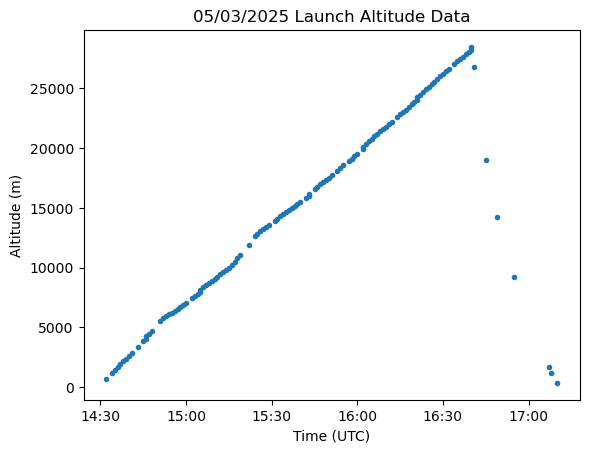

In [8]:
practice_df = pd.read_csv('STAR\Data\Practice\PA-Alpha APRS KD3AVU-2 250503.csv')
practice_df['time'] = pd.to_datetime(practice_df['time'], errors='coerce')
practice_df

plt.plot(practice_df['time'],practice_df['altitude'],'o',markersize=3)
plt.title("05/03/2025 Launch Altitude Data")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

plt.xlabel("Time (UTC)")
plt.ylabel("Altitude (m)")

plt.savefig('practice1.png', bbox_inches='tight')
plt.show()


In [9]:
feb8_df.rename(columns={'RTC_[HMS]':'RTC [H:M:S]'}, inplace=True)
feb8_df


,Events G1,Delta E G1,Events G2,Delta E G2,Temperature [C],Pressure [Pa],Date [MM/DD/YY],RTC [H:M:S],Latitude,Longitude,Altitude,Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Accel-Gyro Temp [c],Mag x,Mag y,Mag z,Time
0,2,1,0,0,6.08,100937.28,2/8/2025,14:58:51,40.17347,-77.40319,140.60001,11,0.47737,0.30748,-9.53899,0.05009,-0.04032,-0.06964,3.0625,-38.01520,6.78164,44.70915,11/10/2024 9:58
1,3,1,0,0,6.09,100938.09,2/8/2025,14:58:53,40.17347,-77.40319,141.00000,11,0.43071,0.24407,-9.66940,0.05009,-0.05131,-0.06475,3.1250,-38.32213,6.78164,43.87606,11/10/2024 9:58
2,4,1,0,0,6.10,100934.77,2/8/2025,14:58:53,40.17347,-77.40319,141.00000,11,0.41635,0.25484,-9.64786,0.05131,-0.07453,-0.06720,3.1250,-38.49751,6.91318,43.97837,11/10/2024 9:58
3,5,1,0,0,6.10,100934.55,2/8/2025,14:58:55,40.17352,-77.40314,144.70000,12,0.50010,0.29073,-9.59402,0.04765,-0.03054,-0.06720,3.1250,-38.87752,7.07395,44.40222,11/10/2024 9:58
4,6,1,0,0,6.11,100935.77,2/8/2025,14:58:55,40.17352,-77.40314,144.70000,12,0.45583,0.23330,-9.64547,0.05742,-0.04887,-0.06475,3.1250,-38.49751,7.96551,43.51067,11/10/2024 9:58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10031,5789,2,6265,0,18.75,8460.78,2/8/2025,16:01:32,39.93391,-76.21854,16680.80078,15,5.58006,-1.86162,4.70190,0.97372,0.62553,1.46608,15.9375,-2.44081,36.49517,-29.53815,11/10/2024 11:01
10032,5789,0,6266,1,18.75,8460.78,2/8/2025,16:01:32,39.93391,-76.21854,16680.80078,15,5.58006,-1.86162,4.70190,0.97372,0.62553,1.46608,15.9375,-2.44081,36.49517,-29.53815,11/10/2024 11:01
10033,5790,1,6266,0,18.75,8459.45,2/8/2025,16:01:32,39.93391,-76.21854,16680.80078,15,1.31366,1.62592,3.74716,1.50029,0.58521,0.83689,16.0000,6.66472,29.62584,-41.37679,11/10/2024 11:01
10034,5790,0,6267,1,18.75,8459.45,2/8/2025,16:01:32,39.93391,-76.21854,16680.80078,15,1.31366,1.62592,3.74716,1.50029,0.58521,0.83689,16.0000,6.66472,29.62584,-41.37679,11/10/2024 11:01


In [10]:
apr4_df

,Events G1,Delta E G1,Events G2,Delta E G2,Temperature [C],Pressure [Pa],Date [MM/DD/YY],RTC [H:M:S],Latitude,Longitude,Altitude,Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Accel-Gyro Temp [c],Mag x,Mag y,Mag z
0,142,1,134,0,32.41,100915.27,4/4/2025,15:41:03,40.27720,-76.63892,136.50000,14,-9.98166,-0.01795,-0.41755,-0.00122,-0.05131,0.00611,32.50000,39.11137,23.91114,12.89097
1,142,0,135,1,32.41,100914.67,4/4/2025,15:41:04,40.27720,-76.63892,136.50000,14,-9.98405,-0.11127,-0.50130,0.00855,-0.02688,-0.00733,32.50781,38.57059,23.61882,13.06635
2,143,1,135,0,32.42,100917.97,4/4/2025,15:41:05,40.27720,-76.63892,136.50000,14,-9.87039,-0.13280,-0.64247,0.00733,-0.02810,-0.00611,32.56250,38.68752,23.54575,12.86174
3,144,1,135,0,32.43,100917.94,4/4/2025,15:41:06,40.27720,-76.63892,136.50000,14,-9.92184,-0.15793,-0.63171,0.00611,-0.03421,-0.00489,32.47266,39.31599,23.69190,12.90558
4,145,1,135,0,32.43,100918.19,4/4/2025,15:41:07,40.27720,-76.63892,136.60001,14,-9.89672,-0.12323,-0.65803,0.00489,-0.03299,-0.00611,32.51172,38.76059,23.44344,13.02251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10597,6569,1,6713,0,25.56,15551.63,4/4/2025,16:41:25,40.19751,-75.65142,18047.90039,15,-15.71367,5.93420,3.96969,3.02623,0.50091,0.54367,25.64844,31.23355,18.83952,-22.06957
10598,6569,0,6714,1,25.56,15551.63,4/4/2025,16:41:25,40.19751,-75.65142,18047.90039,15,-15.71367,5.93420,3.96969,3.02623,0.50091,0.54367,25.64844,31.23355,18.83952,-22.06957
10599,6569,0,6715,1,25.55,15568.82,4/4/2025,16:41:25,40.19751,-75.65142,18047.90039,15,-2.73859,-9.30210,2.05185,7.15079,-6.99807,-1.99142,25.64844,31.61356,-24.40807,8.91552
10600,6569,0,6716,1,25.55,15614.54,4/4/2025,16:41:25,40.19751,-75.65142,18047.90039,15,-21.02813,-4.11087,-4.63609,2.35672,0.93707,-2.39948,25.68359,40.99678,1.08156,-1.27156


C:\Users\Florini\AppData\Local\Temp\ipykernel_10912\1620448857.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  feb8_df[time_col] = pd.to_datetime(feb8_df[time_col], errors='coerce')
C:\Users\Florini\AppData\Local\Temp\ipykernel_10912\1620448857.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  apr4_df[time_col] = pd.to_datetime(apr4_df[time_col], errors='coerce')


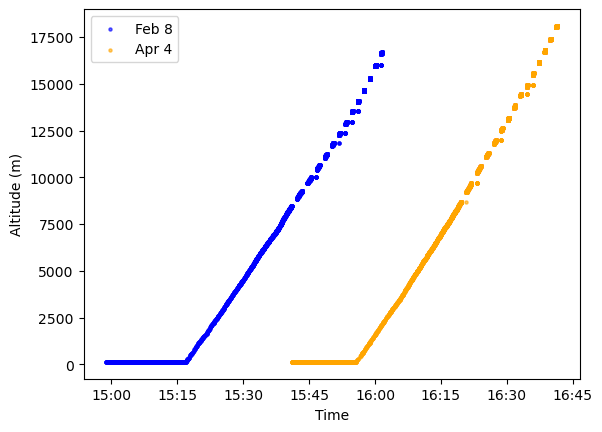

In [11]:
time_col = 'RTC [H:M:S]'
altitude_col = 'Altitude'
fig, ax = plt.subplots()

feb8_df[time_col] = pd.to_datetime(feb8_df[time_col], errors='coerce')
apr4_df[time_col] = pd.to_datetime(apr4_df[time_col], errors='coerce')

ax.scatter(
    feb8_df[time_col], 
    feb8_df[altitude_col], 
    color='blue', 
    label='Feb 8',
    alpha=0.6,
    s=5
)

ax.scatter(
    apr4_df[time_col], 
    apr4_df[altitude_col], 
    color='orange', 
    label='Apr 4',
    alpha=0.6,
    s=5
)

plt.xlabel("Time")
plt.ylabel("Altitude (m)")

ax.legend()

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

plt.savefig('practice2.png', bbox_inches='tight')
plt.show()



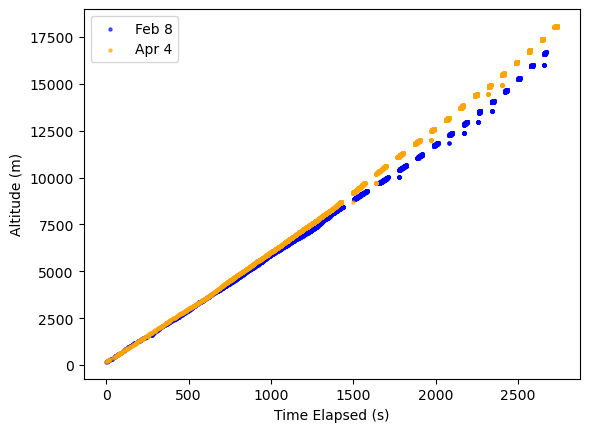

In [12]:
time_col = 'RTC [H:M:S]'
altitude_col = 'Altitude'
fig, ax = plt.subplots()

feb8_df.drop(feb8_df.loc[feb8_df[altitude_col]<160].index, inplace=True)
apr4_df.drop(apr4_df.loc[apr4_df[altitude_col]<160].index, inplace=True)

feb8_df[time_col] = pd.to_datetime(feb8_df[time_col], errors='coerce')
apr4_df[time_col] = pd.to_datetime(apr4_df[time_col], errors='coerce')
feb8_df["elapsed_td"] = (feb8_df[time_col] - feb8_df[time_col].iloc[0]).dt.total_seconds()
apr4_df["elapsed_td"] = (apr4_df[time_col] - apr4_df[time_col].iloc[0]).dt.total_seconds()


time_col = 'elapsed_td'

ax.scatter(
    feb8_df[time_col], 
    feb8_df[altitude_col], 
    color='blue', 
    label='Feb 8',
    alpha=0.6,
    s=5
)

ax.scatter(
    apr4_df[time_col], 
    apr4_df[altitude_col], 
    color='orange', 
    label='Apr 4',
    alpha=0.6,
    s=5
)

plt.xlabel("Time Elapsed (s)")
plt.ylabel("Altitude (m)")

ax.legend()


plt.savefig('practice3.png', bbox_inches='tight')
plt.show()


In [13]:
feb8_df

,Events G1,Delta E G1,Events G2,Delta E G2,Temperature [C],Pressure [Pa],Date [MM/DD/YY],RTC [H:M:S],Latitude,Longitude,Altitude,Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Accel-Gyro Temp [c],Mag x,Mag y,Mag z,Time,elapsed_td
633,316,0,319,1,13.14,100062.17,2/8/2025,2026-07-09 15:17:03,40.17341,-77.40357,168.50000,16,5.51905,-0.24885,8.87976,0.40195,-0.29810,0.07697,10.7500,-35.98363,26.58579,-52.58696,11/10/2024 10:17,0.0
634,316,0,320,1,13.15,99932.77,2/8/2025,2026-07-09 15:17:05,40.17334,-77.40369,181.39999,16,3.12144,-0.86142,7.96690,0.98716,0.03910,2.54731,10.6875,-39.85677,-6.22625,-49.15229,11/10/2024 10:17,2.0
635,317,1,320,0,13.16,99771.35,2/8/2025,2026-07-09 15:17:07,40.17325,-77.40377,196.00000,16,3.95414,0.88176,8.76730,0.82955,-0.00367,1.46241,10.8750,-51.18386,28.69044,-44.31453,11/10/2024 10:17,4.0
636,317,0,321,1,13.17,99633.58,2/8/2025,2026-07-09 15:17:10,40.17312,-77.40388,217.70000,16,4.21256,-0.09332,7.80060,0.37751,-0.08308,0.99938,10.8125,-41.20140,-15.36100,-43.21836,11/10/2024 10:17,7.0
637,317,0,322,1,13.18,99530.06,2/8/2025,2026-07-09 15:17:11,40.17308,-77.40391,226.00000,16,3.14417,-1.23948,9.18006,0.66218,-0.15272,0.55222,10.9375,-58.28705,18.54721,-40.64601,11/10/2024 10:17,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10031,5789,2,6265,0,18.75,8460.78,2/8/2025,2026-07-09 16:01:32,39.93391,-76.21854,16680.80078,15,5.58006,-1.86162,4.70190,0.97372,0.62553,1.46608,15.9375,-2.44081,36.49517,-29.53815,11/10/2024 11:01,2669.0
10032,5789,0,6266,1,18.75,8460.78,2/8/2025,2026-07-09 16:01:32,39.93391,-76.21854,16680.80078,15,5.58006,-1.86162,4.70190,0.97372,0.62553,1.46608,15.9375,-2.44081,36.49517,-29.53815,11/10/2024 11:01,2669.0
10033,5790,1,6266,0,18.75,8459.45,2/8/2025,2026-07-09 16:01:32,39.93391,-76.21854,16680.80078,15,1.31366,1.62592,3.74716,1.50029,0.58521,0.83689,16.0000,6.66472,29.62584,-41.37679,11/10/2024 11:01,2669.0
10034,5790,0,6267,1,18.75,8459.45,2/8/2025,2026-07-09 16:01:32,39.93391,-76.21854,16680.80078,15,1.31366,1.62592,3.74716,1.50029,0.58521,0.83689,16.0000,6.66472,29.62584,-41.37679,11/10/2024 11:01,2669.0


In [14]:
jul20_df

,Events CW1&2,Events CW1&2&3,Temperature [C],Pressure [Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[]
0,1,0,28.85,100514.19,7/20/2025,9:32:33,8.710937,0.00000,0.00000,0.0,0,-0.95115,9.74836,0.75254,0.15638,-0.03665,-0.01466,-48.01228,11.78018,-92.32681,90
1,2,0,29.01,100405.05,7/20/2025,9:32:37,11.985351,0.00000,0.00000,0.0,0,3.31406,8.41077,-1.90588,0.10140,-0.06353,-0.06231,-62.08710,8.90091,-60.87401,90
2,2,1,29.01,100405.05,7/20/2025,9:32:37,11.996093,0.00000,0.00000,0.0,0,3.31406,8.41077,-1.90588,0.10140,-0.06353,-0.06231,-62.08710,8.90091,-60.87401,90
3,3,1,29.07,100402.57,7/20/2025,9:32:39,13.364257,0.00000,0.00000,0.0,0,3.71964,8.50648,-1.82213,0.21014,-0.70372,-0.15272,-61.31248,8.90091,-60.17246,90
4,3,2,29.07,100402.57,7/20/2025,9:32:39,13.370117,0.00000,0.00000,0.0,0,3.71964,8.50648,-1.82213,0.21014,-0.70372,-0.15272,-61.31248,8.90091,-60.17246,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133150,73722,59429,15.20,99457.02,7/20/2025,12:47:02,3079.924783,39.93285,-74.82655,431.8,16,-8.73021,8.55913,5.04527,1.54793,10.03529,-0.91508,-42.70681,20.08185,-63.65098,36
133151,73723,59429,15.20,99545.30,7/20/2025,12:47:03,3080.500954,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36
133152,73723,59430,15.20,99545.30,7/20/2025,12:47:03,3080.521462,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36
133153,73724,59430,15.24,99887.72,7/20/2025,12:47:05,3082.548806,39.93281,-74.82645,383.9,16,-2.74337,4.77368,6.05025,-3.40618,10.78788,-4.62425,-81.13124,14.14791,-98.74305,35


In [15]:
BINSIZE = 60
bins = range(int(jul20_df['Timer[S]'].iloc[0]),int(jul20_df['Timer[S]'].iloc[-1]), BINSIZE)
counts,binEdges = np.histogram(jul20_df['Timer[S]'], bins=bins)
counts
binEdges

array([   8,   68,  128,  188,  248,  308,  368,  428,  488,  548,  608,
        668,  728,  788,  848,  908,  968, 1028, 1088, 1148, 1208, 1268,
       1328, 1388, 1448, 1508, 1568, 1628, 1688, 1748, 1808, 1868, 1928,
       1988, 2048, 2108, 2168, 2228, 2288, 2348, 2408, 2468, 2528, 2588,
       2648, 2708, 2768, 2828, 2888, 2948, 3008, 3068])

In [17]:
def build_counts_per_second(df: pd.DataFrame, y1_col: str, y2_col: str) -> pd.DataFrame:
    rate_df = df[["Timer[S]", y1_col, y2_col]].copy()
    rate_df[y1_col] = rate_df[y1_col].diff().clip(lower=0).fillna(0)
    rate_df[y2_col] = rate_df[y2_col].diff().clip(lower=0).fillna(0)
    rate_df["elapsed_second_bin"] = rate_df["Timer[S]"].astype(int)
    rate_df = rate_df.groupby("elapsed_second_bin", as_index=False)[[y1_col, y2_col]].sum()
    rate_df = rate_df[rate_df["elapsed_second_bin"] <= CUTOFF_SECONDS]
    return rate_df


In [18]:
CUTOFF_SECONDS = 5000
julrate = build_counts_per_second(jul20_df,'Events CW1&2','Events CW1&2&3')
julrate

closest_seconds = jul20_df['Timer[S]'].round().astype(int)

jul20_df['CountPerSec1&2'] = closest_seconds.map(julrate['Events CW1&2'])
jul20_df['Mag'] = np.sqrt(jul20_df['Mag x']**2 + jul20_df['Mag y']**2 + jul20_df['Mag z']**2)

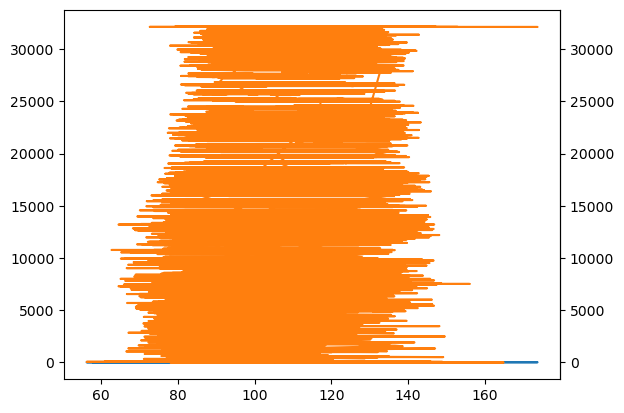

In [18]:
fig, ax = plt.subplots()
ax.plot(jul20_df['Mag'],jul20_df['CountPerSec1&2'])
ax.plot(jul20_df['Mag'],jul20_df['Altitude[m]'])
secax = ax.secondary_yaxis('right')

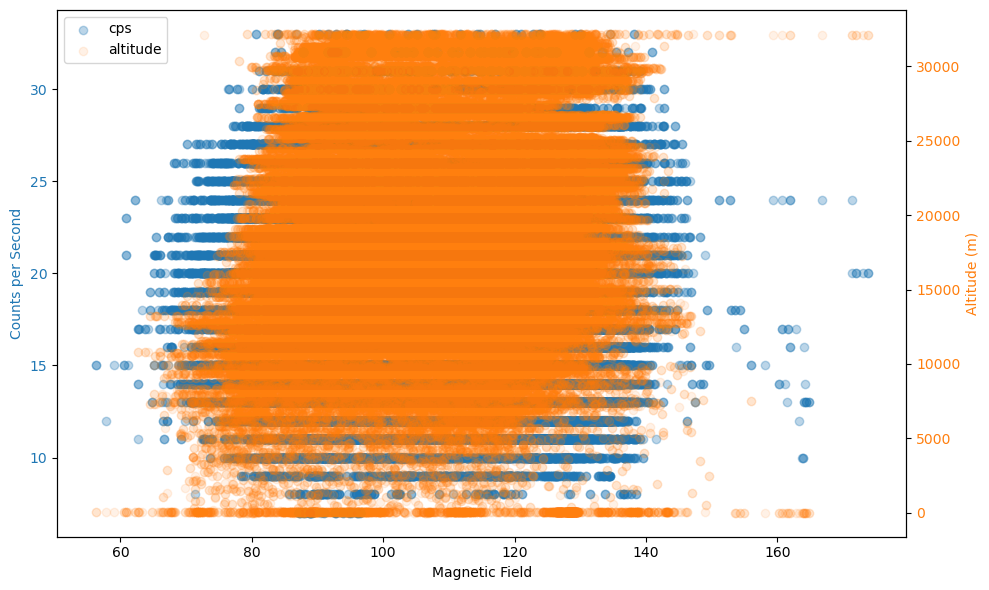

In [19]:
df = jul20_df.copy()

df = df.sort_values('Mag')

fig, ax1 = plt.subplots(figsize=(10, 6))

color1 = 'tab:blue'
ax1.set_xlabel('Magnetic Field')
ax1.set_ylabel('Counts per Second', color=color1)
ax1.scatter(df['Mag'], df['CountPerSec1&2'], color=color1, label='cps',alpha=.3)
ax1.tick_params(axis='y', labelcolor=color1)

ax2 = ax1.twinx()  


color2 = 'tab:orange'
ax2.set_ylabel('Altitude (m)', color=color2)
ax2.scatter(df['Mag'], df['Altitude[m]'], color=color2, label='altitude',alpha=.1)
ax2.tick_params(axis='y', labelcolor=color2)


lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')


fig.tight_layout()

plt.savefig('1.png', bbox_inches='tight')
# Display the plot
plt.show()

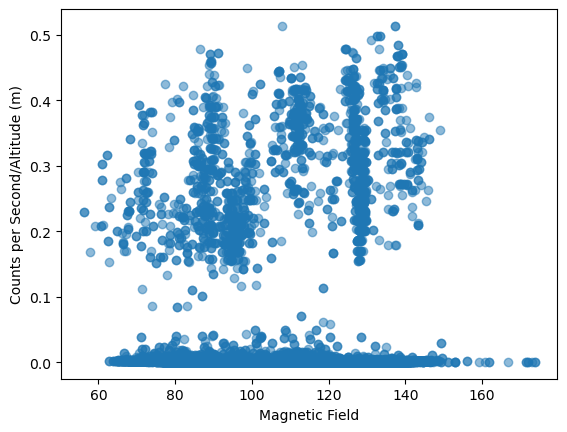

In [20]:
plt.scatter(df['Mag'], df['CountPerSec1&2']/df['Altitude[m]'],alpha=.5)
plt.xlabel('Magnetic Field')
plt.ylabel('Counts per Second/Altitude (m)')
plt.savefig('2.png', bbox_inches='tight')
plt.show()

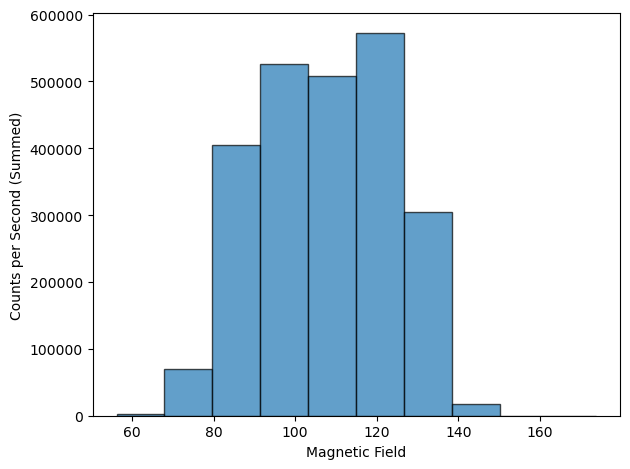

In [24]:
clean_df = df.dropna(subset=['Mag', 'CountPerSec1&2'])
clean_df = clean_df[~np.isinf(clean_df['Mag']) & ~np.isinf(clean_df['CountPerSec1&2'])]
clean_df = clean_df[clean_df['Altitude[m]'] != 0]

#plt.hist(clean_df['Mag'], weights=clean_df['CountPerSec1&2']/clean_df['Altitude[m]'], bins=10, edgecolor='black', alpha=0.7)
plt.hist(clean_df['Mag'], weights=clean_df['CountPerSec1&2'], bins=10, edgecolor='black', alpha=0.7)

# Labeling the axes
plt.xlabel('Magnetic Field')
plt.ylabel('Counts per Second (Summed)')
#plt.ylabel('Counts per Second/Altitude (m) (Summed)')


plt.tight_layout()
plt.savefig('2.png', bbox_inches='tight')
plt.show()

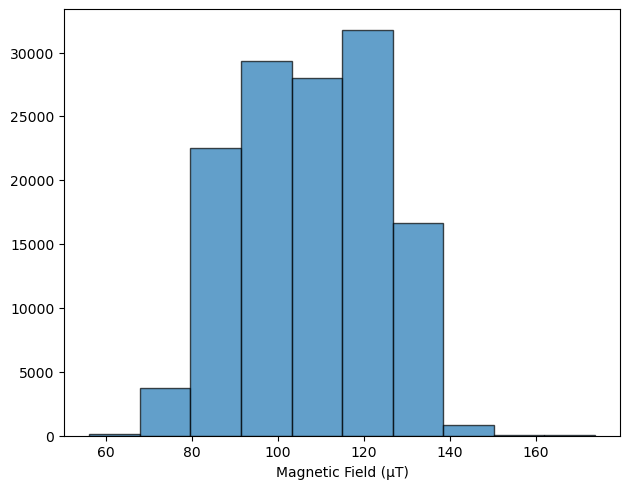

In [22]:
plt.hist(df['Mag'],bins=10, edgecolor='black', alpha=0.7)
plt.tight_layout()
plt.savefig('2.png', bbox_inches='tight')
plt.xlabel('Magnetic Field (μT)')
plt.show()

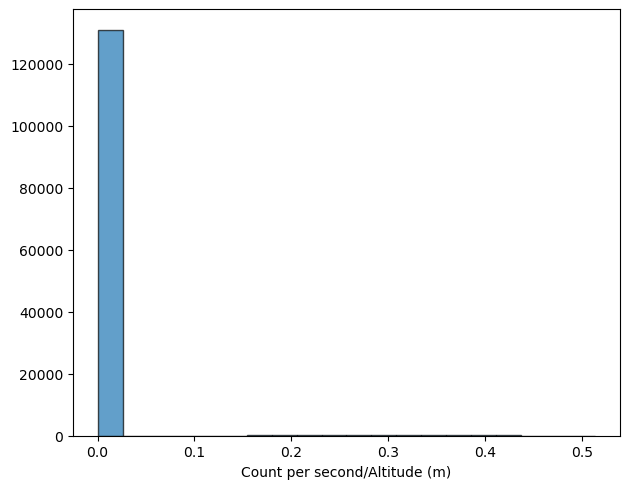

In [47]:
clean_df = df.dropna(subset=['Altitude[m]', 'CountPerSec1&2'])
clean_df = clean_df[clean_df['Altitude[m]'] != 0]
#clean_df['Mag'] = np.sqrt(clean_df['Mag x']**2 + clean_df['Mag y']**2 + clean_df['Mag z']**2)
clean_df['Countoveralt'] = clean_df['CountPerSec1&2']/clean_df['Altitude[m]']
clean_df

plt.hist(clean_df['Countoveralt'],bins=20, edgecolor='black', alpha=0.7)
plt.tight_layout()
plt.savefig('2.png', bbox_inches='tight')
plt.xlabel('Count per second/Altitude (m)')
plt.show()


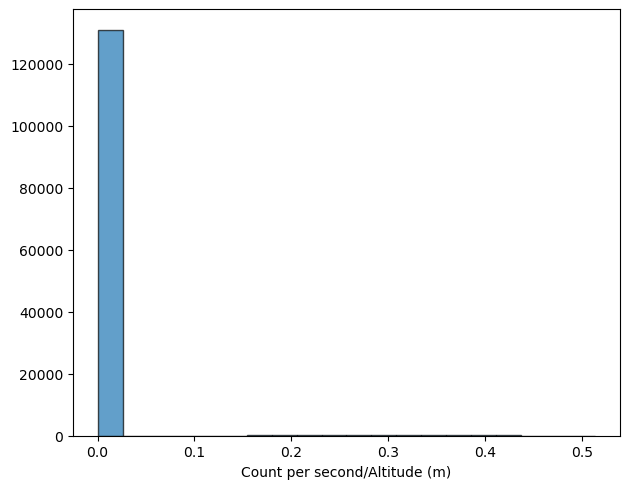

In [45]:
clean_df = df.dropna(subset=['Altitude[m]', 'CountPerSec1&2'])
clean_df = clean_df[clean_df['Altitude[m]'] != 0]
clean_df = clean_df[clean_df['CountPerSec1&2']!=0]
#clean_df['Mag'] = np.sqrt(clean_df['Mag x']**2 + clean_df['Mag y']**2 + clean_df['Mag z']**2)
clean_df['Countoveralt'] = clean_df['CountPerSec1&2']/clean_df['Altitude[m]']
clean_df

plt.hist(clean_df['Countoveralt'],bins=20, edgecolor='black', alpha=0.7)
plt.tight_layout()
plt.savefig('2.png', bbox_inches='tight')
plt.xlabel('Count per second/Altitude (m)')
plt.show()

Trying LOWESS detrending: Fitting a LOWESS model to the relationship between count and altitude, so the residuals can be used to see the effect of other variables with the effect of altitude removed

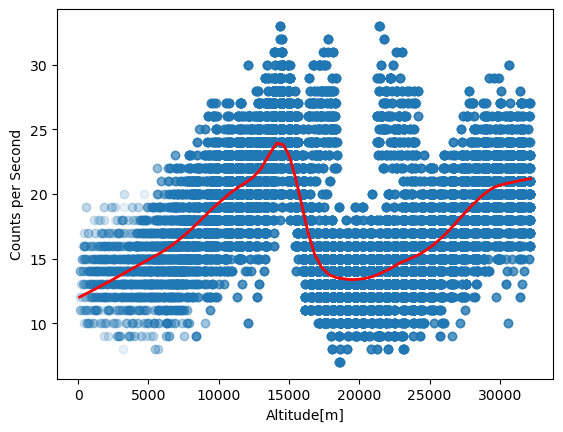

In [75]:
df = df[df['Altitude[m]']>100]

plt.scatter(df['Altitude[m]'], df['CountPerSec1&2'],alpha=.1)
plt.xlabel('Altitude[m]')
plt.ylabel('Counts per Second')
plt.plot(trend[:,0], trend[:,1],
         color='red',
         linewidth=2,
         label='LOWESS')
plt.savefig('2.png', bbox_inches='tight')
plt.show()

In [73]:
from statsmodels.nonparametric.smoothers_lowess import lowess

trend = lowess(df['CountPerSec1&2'], df['Altitude[m]'], frac=0.15)

expected = np.interp(df['Altitude[m]'], trend[:,0], trend[:,1])

df['LOWESS_residuals'] = df['CountPerSec1&2'] - expected

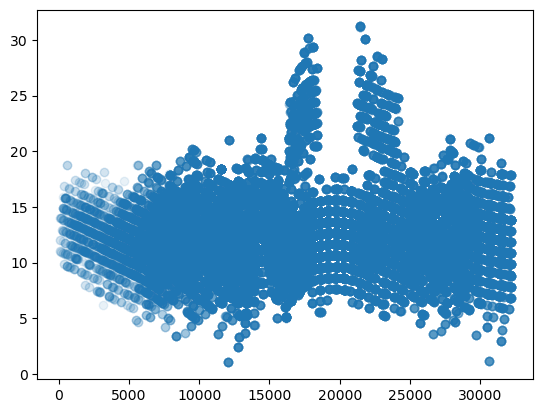

In [74]:
plt.scatter(df['Altitude[m]'], df['LOWESS_residuals']+trend[0, 1],alpha=.1)
plt.savefig('3.png', bbox_inches='tight')
plt.show()

In [3]:
mag_df = pd.read_csv('STAR/Data/Misc/Banana+KCl_90deg-AHD077-datalogger.csv')
mag_df

,Events CW1&2,Events CW1&2&3,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[]
0,1,0,22.44,101549.62,1/1/1970,0:0:10.858,5.864257,0.0,0.0,0.0,0,-10.14318,-0.09332,-0.10768,0.02321,-0.04276,-0.00244,-8.60859,46.60918,-95.87840,74
1,2,0,22.44,101549.62,1/1/1970,0:0:10.887,5.893554,0.0,0.0,0.0,0,-10.07857,-0.08853,-0.09691,0.02199,-0.04154,-0.00244,-8.22859,47.17919,-98.72844,74
2,3,0,22.58,101551.93,1/5/2080,19:59:49.115,10.961914,0.0,0.0,0.0,0,-10.07139,-0.04546,-0.06580,0.02566,-0.04032,-0.00367,-7.84858,46.66764,-94.38760,74
3,4,0,22.64,101551.80,1/5/2080,19:59:56.040,15.090820,0.0,0.0,0.0,0,-10.09652,-0.09332,-0.04546,0.02199,-0.04398,-0.00367,-15.31716,48.91845,-83.86436,74
4,5,0,22.66,101553.77,1/5/2080,19:59:57.553,16.601562,0.0,0.0,0.0,0,-10.06182,-0.05743,-0.06461,0.02321,-0.04276,-0.00367,-12.36481,47.09149,-80.82432,74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7676,6051,1626,24.53,101495.05,2/27/2026,13:46:46.495,202.342252,0.0,0.0,0.0,0,-10.12044,-0.10768,-0.04068,0.00977,-0.04765,-0.01344,-5.80240,46.08302,-94.24145,42
7677,6052,1626,24.53,101492.30,2/27/2026,13:46:48.091,203.635221,0.0,0.0,0.0,0,-10.05584,-0.07777,-0.08255,0.02688,-0.03543,-0.01100,-5.77317,45.39608,-94.97223,42
7678,6052,1627,24.53,101492.30,2/27/2026,13:46:48.091,203.653776,0.0,0.0,0.0,0,-10.05584,-0.07777,-0.08255,0.02688,-0.03543,-0.01100,-5.77317,45.39608,-94.97223,42
7679,6053,1627,24.55,101496.20,2/27/2026,13:46:50.085,205.926237,0.0,0.0,0.0,0,-9.97328,0.02752,-0.08973,0.05620,0.01833,0.12950,-6.38702,45.83455,-94.00760,42


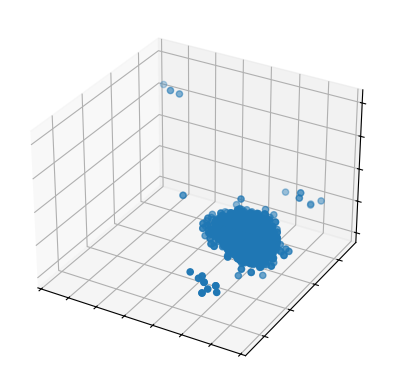

In [6]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(mag_df['Mag x'], mag_df['Mag y'], mag_df['Mag z'])
ax.set(xticklabels=[],
       yticklabels=[],
       zticklabels=[])

plt.show()

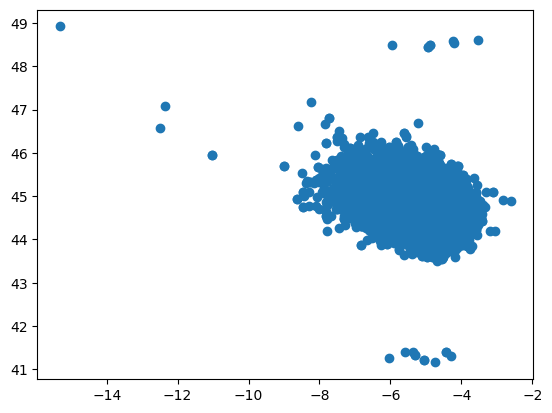

In [7]:
plt.scatter(mag_df['Mag x'], mag_df['Mag y'])

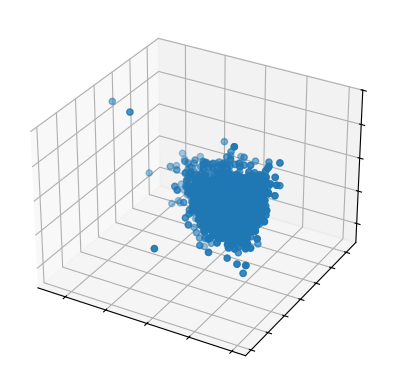

In [11]:
mag_df2 = pd.read_csv('STAR/Data/Misc/2HR_Ground_Test_0_Deg_DATALOGGER.csv')
mag_df3 = pd.read_csv('STAR/Data/Misc/2HR_Ground_Test_45_Deg_DATALOGGER.csv')

mag_df4 = pd.concat([mag_df2,mag_df3])
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(mag_df3['Mag x'], mag_df3['Mag y'], mag_df3['Mag z'])
ax.set(xticklabels=[],
       yticklabels=[],
       zticklabels=[])

plt.show()

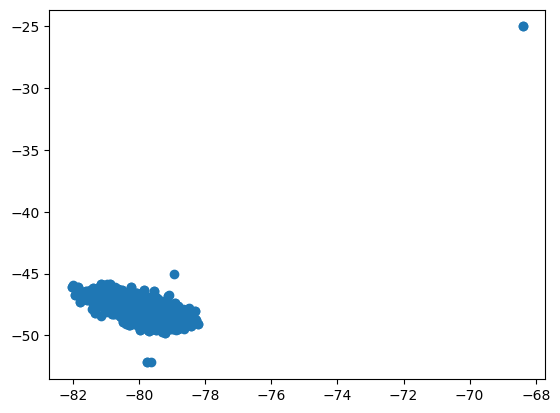

In [12]:
plt.scatter(mag_df2['Mag x'], mag_df2['Mag y'])

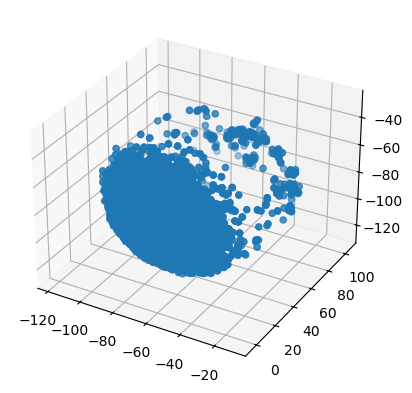

In [19]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(jul20_df['Mag x'],jul20_df['Mag y'], jul20_df['Mag z'])

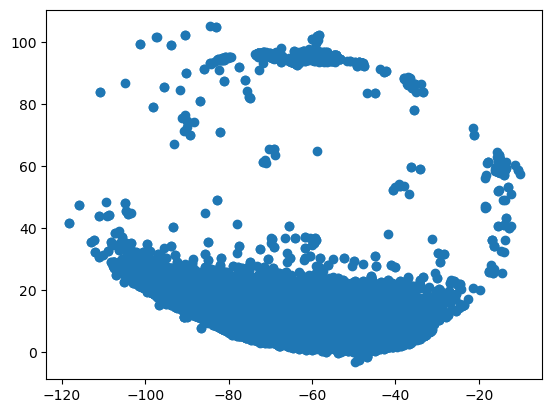

In [20]:
plt.scatter(jul20_df['Mag x'], jul20_df['Mag y'])

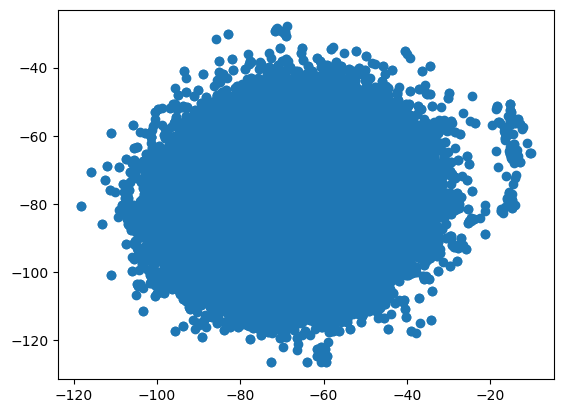

In [21]:
plt.scatter(jul20_df['Mag x'], jul20_df['Mag z'])

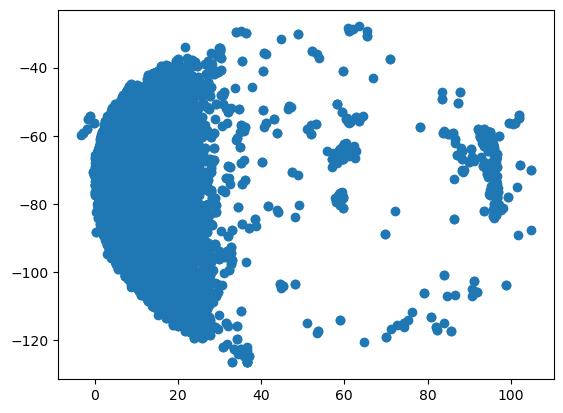

In [22]:
plt.scatter(jul20_df['Mag y'], jul20_df['Mag z'])

In [24]:
jul20_df[jul20_df['Altitude[m]']>1]

,Events CW1&2,Events CW1&2&3,Temperature [C],Pressure [Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[],CountPerSec1&2,Mag
69,46,24,31.52,100378.59,7/20/2025,9:34:12,106.000000,40.11984,-75.55370,83.6,6,-9.36192,-1.66899,-3.86082,0.05253,-0.19303,-0.07330,-36.29056,59.69015,-40.85063,89,15.0,80.923993
70,46,25,31.52,100378.59,7/20/2025,9:34:12,106.009765,40.11984,-75.55370,83.6,6,-9.36192,-1.66899,-3.86082,0.05253,-0.19303,-0.07330,-36.29056,59.69015,-40.85063,89,15.0,80.923993
71,47,25,31.61,100380.33,7/20/2025,9:34:17,111.499023,40.11982,-75.55366,80.3,6,-8.69313,-0.56471,-4.46620,-0.04276,-0.16005,0.26023,-39.16983,54.01929,-37.09441,89,19.0,76.343661
72,48,25,31.67,100383.03,7/20/2025,9:34:22,116.541015,40.11981,-75.55361,79.4,6,-8.48375,-1.04207,-5.50110,0.03299,-0.15760,0.20403,-40.51447,52.30926,-35.10669,89,12.0,74.901006
73,48,26,31.67,100383.03,7/20/2025,9:34:22,116.550781,40.11981,-75.55361,79.4,6,-8.48375,-1.04207,-5.50110,0.03299,-0.15760,0.20403,-40.51447,52.30926,-35.10669,89,12.0,74.901006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133150,73722,59429,15.20,99457.02,7/20/2025,12:47:02,3079.924783,39.93285,-74.82655,431.8,16,-8.73021,8.55913,5.04527,1.54793,10.03529,-0.91508,-42.70681,20.08185,-63.65098,36,11.0,79.237615
133151,73723,59429,15.20,99545.30,7/20/2025,12:47:03,3080.500954,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36,10.0,122.281641
133152,73723,59430,15.20,99545.30,7/20/2025,12:47:03,3080.521462,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36,10.0,122.281641
133153,73724,59430,15.24,99887.72,7/20/2025,12:47:05,3082.548806,39.93281,-74.82645,383.9,16,-2.74337,4.77368,6.05025,-3.40618,10.78788,-4.62425,-81.13124,14.14791,-98.74305,35,15.0,128.579281


In [29]:
jul20_df[jul20_df['Timer[S]']>2000]

,Events CW1&2,Events CW1&2&3,Temperature [C],Pressure [Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Timer[S],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[],CountPerSec1&2,Mag
1248,811,438,40.88,100354.49,7/20/2025,10:06:01,2013.196289,40.11980,-75.55353,61.5,18,-9.65384,-0.40558,1.97647,0.02688,-0.03421,0.02321,-14.19176,59.77784,-64.54253,78,24.0,89.109676
1249,812,438,40.89,100355.42,7/20/2025,10:06:02,2013.485351,40.11980,-75.55353,61.5,18,-9.69691,-0.41396,1.98844,0.02321,-0.02932,-0.00733,-13.97252,59.51476,-64.55714,78,24.0,88.909293
1250,813,438,40.88,100350.67,7/20/2025,10:06:02,2013.641601,40.11980,-75.55353,61.5,18,-9.73520,-0.44148,2.02552,0.02199,-0.03176,-0.01222,-13.92868,59.39783,-66.07716,78,19.0,89.934984
1251,814,438,40.91,100349.72,7/20/2025,10:06:10,2021.636718,40.11979,-75.55353,61.6,18,-9.82373,-0.64367,1.72881,0.02199,-0.03421,-0.01100,-14.84946,60.24554,-62.86174,77,26.0,88.326836
1252,815,438,40.92,100353.66,7/20/2025,10:06:11,2023.000976,40.11979,-75.55353,61.6,18,-9.81775,-0.64606,1.72762,0.02321,-0.03299,-0.01100,-14.22099,59.89476,-62.52558,77,25.0,87.744327
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133150,73722,59429,15.20,99457.02,7/20/2025,12:47:02,3079.924783,39.93285,-74.82655,431.8,16,-8.73021,8.55913,5.04527,1.54793,10.03529,-0.91508,-42.70681,20.08185,-63.65098,36,11.0,79.237615
133151,73723,59429,15.20,99545.30,7/20/2025,12:47:03,3080.500954,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36,10.0,122.281641
133152,73723,59430,15.20,99545.30,7/20/2025,12:47:03,3080.521462,39.93283,-74.82652,415.9,16,-6.64726,13.47997,5.86600,2.23454,6.58146,-3.83990,-52.23619,22.31804,-108.28705,36,10.0,122.281641
133153,73724,59430,15.24,99887.72,7/20/2025,12:47:05,3082.548806,39.93281,-74.82645,383.9,16,-2.74337,4.77368,6.05025,-3.40618,10.78788,-4.62425,-81.13124,14.14791,-98.74305,35,15.0,128.579281


In [31]:
feb8_df['Mag'] = np.sqrt(feb8_df['Mag x']**2 + feb8_df['Mag y']**2 + feb8_df['Mag z']**2)

In [46]:
feb8_df_early = feb8_df[feb8_df['Altitude']>2000]
feb8_df_early = feb8_df_early[feb8_df_early['Altitude']<3000]

In [47]:
feb8_df_early

,Events G1,Delta E G1,Events G2,Delta E G2,Temperature [C],Pressure [Pa],Date [MM/DD/YY],RTC_[HMS],Latitude,Longitude,Altitude,Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Accel-Gyro Temp [c],Mag x,Mag y,Mag z,Time,Mag
764,371,1,395,0,14.71,79252.75,2/8/2025,15:22:37,40.17999,-77.39652,2032.19995,16,3.68255,-0.15793,9.29612,0.43371,-0.15394,0.76969,12.2500,-21.49956,13.09559,-55.83163,11/10/2024 10:22,61.244563
765,372,1,395,0,14.71,79222.70,2/8/2025,15:22:37,40.17999,-77.39652,2032.19995,16,3.90628,-0.24287,7.95255,0.60353,-0.14783,1.16553,12.2500,-27.11195,-0.42385,-54.88161,11/10/2024 10:22,61.214611
766,372,0,396,1,14.71,79177.39,2/8/2025,15:22:38,40.18002,-77.39639,2038.30005,16,3.95653,-0.76690,8.92642,0.49724,-0.12828,0.73304,12.2500,-45.76147,-2.33850,-45.79070,11/10/2024 10:22,64.779387
767,373,1,396,0,14.72,79100.30,2/8/2025,15:22:40,40.18004,-77.39612,2047.80005,16,3.67897,-0.73220,8.93001,0.37874,-0.06353,0.59376,12.2500,-54.95469,7.73166,-42.01988,11/10/2024 10:22,69.609388
768,373,0,397,1,14.73,79021.81,2/8/2025,15:22:42,40.18006,-77.39584,2059.50000,16,2.95992,-0.44626,8.73141,0.41294,-0.01833,0.67317,12.2500,-50.04385,17.12949,-46.98918,11/10/2024 10:22,70.751603
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
863,413,0,452,1,15.39,70451.22,2/8/2025,15:25:29,40.18631,-77.36794,2964.80005,16,5.38624,-0.75374,9.67658,1.28404,0.01344,2.52776,12.9375,-58.82782,3.04005,-38.19059,11/10/2024 10:25,70.203102
864,413,0,453,1,15.40,70288.75,2/8/2025,15:25:32,40.18649,-77.36714,2981.10010,16,3.48993,-0.41157,7.76950,0.15272,-0.09896,-0.62797,12.9375,-38.67290,11.64864,-52.66004,11/10/2024 10:25,66.365381
865,414,1,453,0,15.40,70250.45,2/8/2025,15:25:33,40.18653,-77.36690,2985.80005,16,3.75912,0.55992,7.99681,-0.29199,0.32009,-0.62553,12.8750,-29.49430,10.49401,-55.04239,11/10/2024 10:25,63.322213
866,414,0,454,1,15.41,70126.56,2/8/2025,15:25:35,40.18652,-77.36637,2992.89990,16,4.03430,-0.69870,8.84387,0.42761,0.16005,1.20218,12.9375,-51.27156,-3.55159,-43.27682,11/10/2024 10:25,67.188316


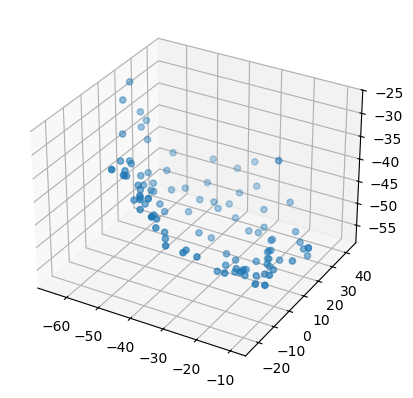

In [48]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(feb8_df_early['Mag x'],feb8_df_early['Mag y'], feb8_df_early['Mag z'])

Experiment in correcting uncalibrated magnetometer data by fitting it to a sphere

If it was calibrated correctly, there would be a sphere created from the data points when the device is rotated in all directions, would be centered at 0,0,0

This assumes that the data points from a period of time where the altitude does not vary much and the gyro data points indicate the device was angled/shaken in several different ways form part of this sphere, and the only distortion is hard iron distortion

This code is meant to remove the offset from the hard iron distortion by finding the offset from the center of the sphere fit to the data points and (0,0,0), then subtracting the x y and z offsets from the 'Mag x', 'Mag y', 'Mag z' columns, however, I have no idea if this actually makes sense or works

Sphere fitting code from https://jekel.me/2015/Least-Squares-Sphere-Fit/ 

In [51]:
import numpy as np
#	fit a sphere to X,Y, and Z data points
#	returns the radius and center points of
#	the best fit sphere
def sphereFit(spX,spY,spZ):
    #   Assemble the A matrix
    spX = np.array(spX)
    spY = np.array(spY)
    spZ = np.array(spZ)
    A = np.zeros((len(spX),4))
    A[:,0] = spX*2
    A[:,1] = spY*2
    A[:,2] = spZ*2
    A[:,3] = 1

    #   Assemble the f matrix
    f = np.zeros((len(spX),1))
    f[:,0] = (spX*spX) + (spY*spY) + (spZ*spZ)
    C, residules, rank, singval = np.linalg.lstsq(A,f)

    #   solve for the radius
    t = (C[0]*C[0])+(C[1]*C[1])+(C[2]*C[2])+C[3]
    radius = np.sqrt(t)

    return radius, C[0], C[1], C[2]

In [52]:
sphereFit(feb8_df_early['Mag x'],feb8_df_early['Mag y'],feb8_df_early['Mag z'])

(array([47.63052454]),
 array([-22.00331799]),
 array([11.91693041]),
 array([-8.27917232]))

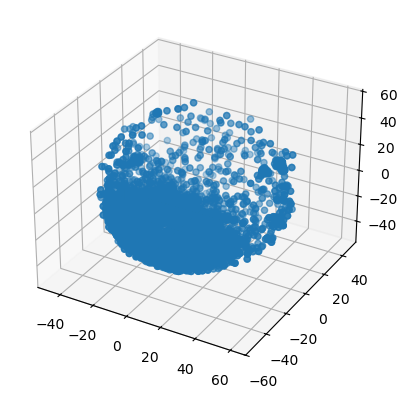

In [54]:
feb8_df['Corrected Mag x'] = feb8_df['Mag x'] - -22.00331799
feb8_df['Corrected Mag y'] = feb8_df['Mag y'] - 11.91693041
feb8_df['Corrected Mag z'] = feb8_df['Mag z'] - -8.27917232

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(feb8_df['Corrected Mag x'], feb8_df['Corrected Mag y'], feb8_df['Corrected Mag z'])

In [56]:
feb8_df['Corrected Mag'] = np.sqrt(feb8_df['Corrected Mag x']**2 + feb8_df['Corrected Mag y']**2 + feb8_df['Corrected Mag z']**2)

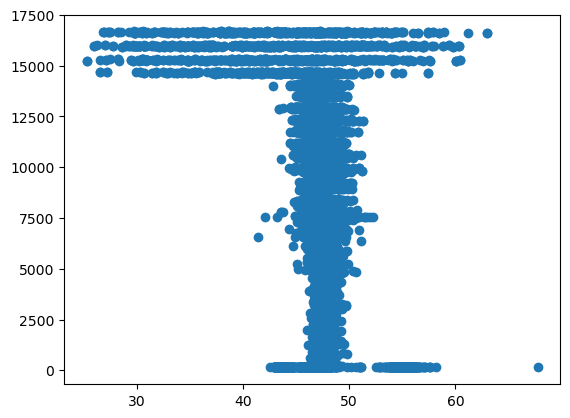

In [58]:
plt.scatter(feb8_df['Corrected Mag'],feb8_df['Altitude'])

In [60]:
n15_pa_df = pd.read_csv('STAR/Data/Nov15/CW/PA/Annafy_DF_5PA007.csv')
n15_pa_df

,Counts Per Second,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[%]
0,1,20.37,97251.89,11/15/2025,14:51:42.079,0.0000,0.00000,0.0,0,9.24228,3.12622,-4.36331,-0.42516,-2.58274,-2.28464,-96.18532,18.59105,-7.00088,90
1,1,20.39,97248.93,11/15/2025,14:51:43.135,0.0000,0.00000,0.0,0,7.54098,4.54636,-4.44108,0.19914,0.00000,0.00367,-92.70680,14.84946,-2.47004,90
2,1,20.42,97253.00,11/15/2025,14:51:44.509,0.0000,0.00000,0.0,0,7.24666,4.80838,-4.96870,0.01955,-0.14661,-0.11606,-91.65449,13.38790,-3.28851,90
3,1,20.43,97252.22,11/15/2025,14:51:45.109,0.0000,0.00000,0.0,0,7.16770,5.08714,-4.03908,-0.15027,-0.07086,0.05131,-91.40602,13.02251,-6.65010,90
4,1,20.44,97250.77,11/15/2025,14:51:45.300,0.0000,0.00000,0.0,0,6.88894,4.93280,-4.16231,-0.23213,-0.19059,-0.00977,-91.53756,13.28559,-7.77550,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22608,1,19.84,99066.69,11/15/2025,21:8:52.426,40.1132,-76.16986,96.0,13,-1.64387,8.59263,-4.50569,-0.13683,0.01100,-0.04276,-43.26220,-8.37474,-18.51798,40
22609,1,19.86,99069.27,11/15/2025,21:8:55.317,40.1132,-76.16986,96.0,12,0.18066,5.98325,-7.68814,0.36408,-0.16249,-0.27000,-70.05261,-6.75241,-4.98392,40
22610,1,19.86,99063.95,11/15/2025,21:8:55.634,40.1132,-76.16986,96.0,12,1.87238,6.72024,-6.22493,0.26756,-1.02259,1.44653,-82.89973,-1.57849,-5.14469,40
22611,1,19.86,99066.35,11/15/2025,21:8:57.005,40.1132,-76.16986,96.0,12,-5.18285,3.14895,-8.40240,-0.27367,0.49236,0.51557,-26.14732,5.15931,0.24847,40


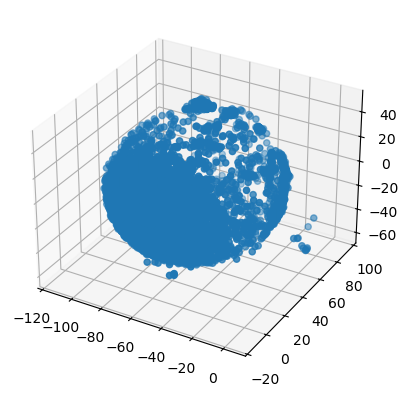

In [61]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(n15_pa_df['Mag x'],n15_pa_df['Mag y'], n15_pa_df['Mag z'])

In [66]:
n15_early = n15_pa_df[n15_pa_df['Altitude[m]']>2000]
n15_early = n15_early[n15_early['Altitude[m]']<3000]
n15_early

,Counts Per Second,Temperature[C],Pressure[Pa],Date[MM/DD/YYYY],RTC[H:M:S EST],Latitude,Longitude,Altitude[m],Sats,Accel x,Accel y,Accel z,Gyro x,Gyro y,Gyro z,Mag x,Mag y,Mag z,Battery[%]
3741,1,25.49,75853.31,11/15/2025,15:54:17.107,40.65421,-77.97387,2009.8,14,-0.49173,9.03530,0.52283,0.11973,-1.89979,0.40928,-72.34727,1.12540,-15.90178,77
3742,1,25.49,75808.48,11/15/2025,15:54:18.026,40.65417,-77.97370,2016.1,14,0.03111,10.06182,3.76870,0.36041,-7.20210,0.44593,-25.73809,-0.45308,-7.60012,77
3743,1,25.49,75784.67,11/15/2025,15:54:18.431,40.65417,-77.97370,2016.1,14,2.85344,11.44248,-0.47498,-0.55589,-5.96327,0.17593,-74.37884,1.31540,1.18386,77
3744,1,25.50,75722.21,11/15/2025,15:54:19.410,40.65416,-77.97356,2023.2,14,1.07318,10.83231,3.01735,-0.06353,-4.40556,0.51191,-71.77725,2.16311,11.19556,77
3745,1,25.49,75699.77,11/15/2025,15:54:19.722,40.65416,-77.97356,2023.2,14,0.28714,10.65285,-0.07777,-0.16860,-4.80995,0.13928,-37.43058,0.73078,20.30108,77
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10275,1,1.76,81122.56,11/15/2025,17:43:01.178,40.11174,-76.19037,2028.9,13,-0.28594,7.30409,6.79083,0.40684,3.07998,0.32254,-79.33353,5.40778,-24.05729,60
10276,1,1.77,81238.49,11/15/2025,17:43:03.139,40.11160,-76.19013,2012.8,13,1.73958,10.05823,-1.69531,0.16738,-4.34814,1.29503,-86.12978,16.64718,-42.37065,60
10277,1,1.78,81290.71,11/15/2025,17:43:03.480,40.11160,-76.19013,2012.8,13,3.72084,11.54058,4.85384,0.12339,-9.10678,0.35186,-43.62759,17.69950,16.06256,60
10278,1,1.78,81361.20,11/15/2025,17:43:04.313,40.11151,-76.18992,2008.8,13,6.04547,12.80400,-9.66820,-0.14294,-2.73790,0.46792,-79.87430,15.01023,18.44490,60


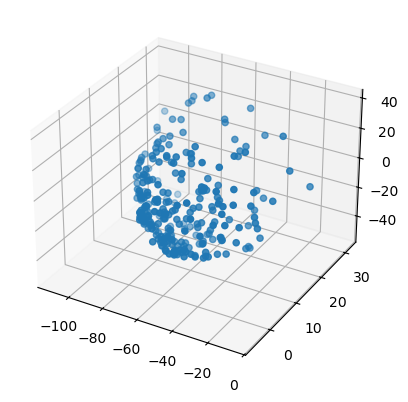

In [68]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(n15_early['Mag x'],n15_early['Mag y'], n15_early['Mag z'])

In [70]:
r, x0, y0, z0 = sphereFit(n15_early['Mag x'],n15_early['Mag y'],n15_early['Mag z'])

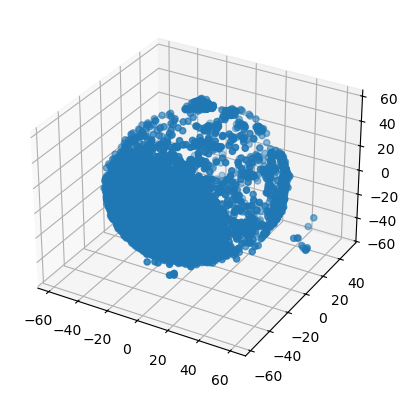

In [71]:
n15_pa_df['Corrected Mag x'] = n15_pa_df['Mag x'] - x0
n15_pa_df['Corrected Mag y'] = n15_pa_df['Mag y'] - y0
n15_pa_df['Corrected Mag z'] = n15_pa_df['Mag z'] - z0

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(n15_pa_df['Corrected Mag x'], n15_pa_df['Corrected Mag y'], n15_pa_df['Corrected Mag z'])

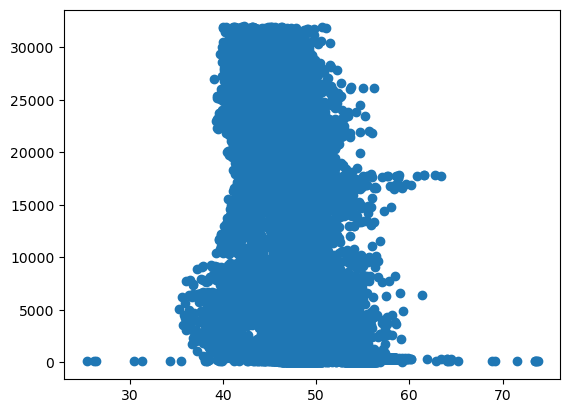

In [73]:
n15_pa_df['Corrected Mag'] = np.sqrt(n15_pa_df['Corrected Mag x']**2 + n15_pa_df['Corrected Mag y']**2 + n15_pa_df['Corrected Mag z']**2)
plt.scatter(n15_pa_df['Corrected Mag'],n15_pa_df['Altitude[m]'])

In [5]:
lowess_df = getCosmicWatch_df('STAR/Data/May31/PA/AxLab_M_029.txt')
lowess_df

[1.00000e+00 2.00000e+00 3.00000e+00 ... 3.36048e+05 3.36049e+05
 3.36050e+05]


,Timestamp_s,Counts_Per_Second,Rate_Error,Raw_Counts


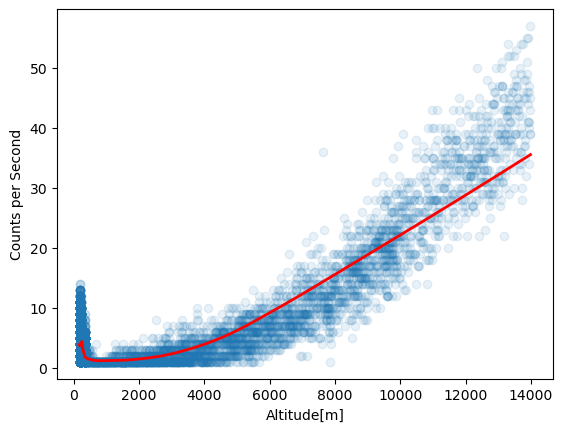

In [11]:
from statsmodels.nonparametric.smoothers_lowess import lowess

lowess_df = lowess_df[lowess_df['Counts Per Second']<100]
lowess_df = lowess_df[lowess_df['Altitude[m]']<14000]
lowess_df = lowess_df[lowess_df['Altitude[m]']>100]

trend = lowess(lowess_df['Counts Per Second'], lowess_df['Altitude[m]'], frac=0.15)

expected = np.interp(lowess_df['Altitude[m]'], trend[:,0], trend[:,1])

lowess_df['LOWESS_residuals'] = lowess_df['Counts Per Second'] - expected


plt.scatter(lowess_df['Altitude[m]'], lowess_df['Counts Per Second'],alpha=.1)
plt.xlabel('Altitude[m]')
plt.ylabel('Counts per Second')
plt.plot(trend[:,0], trend[:,1],
         color='red',
         linewidth=2,
         label='LOWESS')
plt.savefig('2.png', bbox_inches='tight')
plt.show()

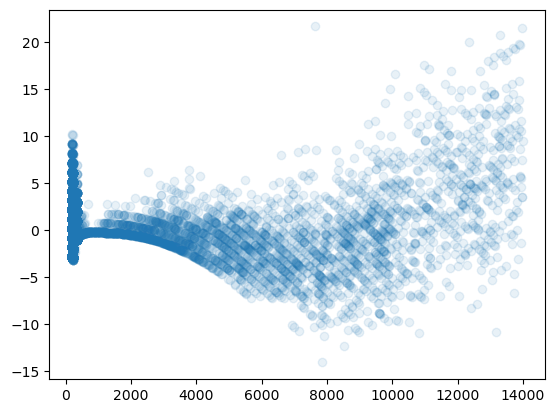

In [13]:
#plt.scatter(lowess_df['Altitude[m]'], lowess_df['LOWESS_residuals']+trend[0, 1],alpha=.1)
plt.scatter(lowess_df['Altitude[m]'], lowess_df['LOWESS_residuals'],alpha=.1)
plt.savefig('3.png', bbox_inches='tight')
plt.show()

In [4]:
def getCosmicWatch_df(fname,_BINSIZE_=60,_TIMEOFFSET_=0):
    # output file:
    # [count] [time stamp] [ADC] [SiPM] [deadtime] [temp]
    count,time,coin,adc,sipm,deadt,temp,press = np.genfromtxt(fname=fname,skip_header=6,unpack=True)
    ####
    #### calculate the count rate in chunks of _BINSIZE_ (above)
    ####
    event_deadt = np.diff(np.append([0],deadt))
    # total_time = max(time)
    # total_deadt = max(deadt)
    # #total_counts = max(count)-min(count)
    # total_counts = len(count)

    ## change time from milliseconds to seconds
    time_s = time/1000.
    event_deadt_s = event_deadt/1000.
    #total_time_s = total_time/1000.
    #total_deadt_s = total_deadt/1000.
    event_livetime_s = np.diff(np.append([0],time_s)) - event_deadt_s

    ####
    #### bin the data for nice plots
    ####
    bins = range(int(min(time_s)),int(max(time_s)),_BINSIZE_)
    counts,binEdges = np.histogram(time_s, bins=bins)
    bin_livetime,binEdges = np.histogram(time_s,bins=bins,weights=event_livetime_s)
    
    
    
    #print(bin_livetime)

    bincenters = 0.5*(binEdges[1:]+binEdges[:-1])
    #binned_counts = counts
    #binned_counts_err = np.sqrt(counts)
    
    #binned_count_rate = counts/bin_livetime
    #binned_count_rate_err = np.sqrt(counts)/bin_livetime

    #CHANGED to prevent error when bin_livetime is 0, ends up being 0/0 which ERRORS
    
    with np.errstate(divide="ignore", invalid="ignore"):
        binned_count_rate = np.where(bin_livetime > 0, counts / bin_livetime, 0)
        binned_count_rate_err = np.where(
            bin_livetime > 0, np.sqrt(counts) / bin_livetime, 0
        )
    
    binned_time = bincenters/_BINSIZE_
    
    
    #return binned_time+_TIMEOFFSET_,binned_count_rate,binned_count_rate_err


    df = pd.DataFrame(
        {
            "Timestamp_s": bincenters + _TIMEOFFSET_,
            "Counts_Per_Second": binned_count_rate,
            "Rate_Error": binned_count_rate_err,
            "Raw_Counts": counts
        }
    )

    return df






In [26]:
_BINSIZE_ = 60
_CWTIMEOFFSET_ = -8.7 ## for syncing between GC, CW, & FC

binned_time,binned_count_rate,binned_count_rate_err = getCosmicWatch("STAR/Data/May31/PA/AxLab_M_029.txt",_BINSIZE_,_CWTIMEOFFSET_)



[1.00000e+00 2.00000e+00 3.00000e+00 ... 3.36048e+05 3.36049e+05
 3.36050e+05]


[]
Shape: (3, 0)
